# H4: is the effect of denoising on scan–rescan CoV moderated by off-resonance?

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import figs   # figs.py, next to this notebook

# Pipeline outputs (../pipeline/run_pipeline.sh): set RR_DERIV and RR_MANIFEST, or edit here
DERIV = Path(os.environ.get("RR_DERIV", "/path/to/derivatives"))
MANIFEST = Path(os.environ.get("RR_MANIFEST", "/path/to/ds004712_meta/sessions_manifest.csv"))
FIGS = DERIV / "analysis" / "figures" / "stage2"
EXPL = DERIV / "analysis" / "exploratory"
METRICS = ("FA", "MD", "MK")
pd.set_option("display.width", 200, "display.max_columns", 30)
plt.rcParams["figure.dpi"] = 60   # inline size; saved PNGs are 300 dpi
info = figs.pair_info(DERIV)


## Registered results

In [2]:
nat = pd.read_csv(DERIV / "analysis" / "descriptives" / "h4_native.csv")
nat["Hypothesis"] = [figs.hyp_label("H4", lv, m) for lv, m in zip(nat.level, nat.metric)]
t = figs.results_table(DERIV, "H4").merge(nat, on=["Hypothesis", "pair"])
t["scanner"] = t.repeat_scanner.str.split("_").str[0]
TAG = {"supports H4": "H4", "supports null": "null", "inconclusive (BF10 > 10, opposite sign)": "opposite",
       "inconclusive": "inconclusive"}
print("converged:", ", ".join(t.converged.unique()), "| verdicts:", t.verdict.map(TAG).value_counts().to_dict())
t["cell"] = [f"{b} BF {bf} ({TAG[v]})" for b, bf, v in zip(t["beta1 [95% CrI]"], t.BF10, t.verdict)]
SCANNERS = ["Ingenia32", "Premier48", "Premier21", "Prisma64", "Prisma32"]
t.pivot(index="Hypothesis", columns="scanner", values="cell")[SCANNERS].rename_axis(columns="β1 [95% CrI] BF10 (verdict)")

converged: yes | verdicts: {'opposite': 12, 'null': 11, 'H4': 5, 'inconclusive': 2}


β1 [95% CrI] BF10 (verdict),Ingenia32,Premier48,Premier21,Prisma64,Prisma32
Hypothesis,,,,,
H4a – FA voxel-wise,"+0.00260 [+0.00151, +0.00372] BF 26.7 (H4)","+0.00031 [-0.00026, +0.00091] BF 0.001 (null)","-0.00051 [-0.00102, -0.00003] BF 0.002 (null)","-0.00026 [-0.00093, +0.00040] BF 0.000 (null)","-0.00035 [-0.00094, +0.00023] BF 0.001 (null)"
H4a – MD voxel-wise,"+0.00096 [+0.00037, +0.00155] BF 0.048 (null)","-0.00244 [-0.00285, -0.00201] BF >100 (opposite)","-0.00152 [-0.00175, -0.00129] BF >100 (opposite)","-0.00133 [-0.00176, -0.00091] BF >100 (opposite)","-0.00099 [-0.00133, -0.00065] BF >100 (opposite)"
H4a – MK voxel-wise,"+0.00476 [+0.00293, +0.00659] BF >100 (H4)","-0.00443 [-0.00550, -0.00336] BF >100 (opposite)","-0.00667 [-0.00735, -0.00598] BF >100 (opposite)","-0.00686 [-0.00796, -0.00572] BF >100 (opposite)","-0.00717 [-0.00803, -0.00632] BF >100 (opposite)"
H4b – FA ROI-wise,"+0.00576 [+0.00396, +0.00764] BF >100 (H4)","+0.00254 [+0.00144, +0.00364] BF 12.3 (H4)","+0.00019 [-0.00084, +0.00121] BF 0.001 (null)","-0.00033 [-0.00120, +0.00052] BF 0.001 (null)","-0.00098 [-0.00192, -0.00003] BF 0.004 (null)"
H4b – MD ROI-wise,"+0.00265 [+0.00171, +0.00360] BF >100 (H4)","-0.00163 [-0.00231, -0.00097] BF 30.5 (opposite)","-0.00022 [-0.00062, +0.00017] BF 0.000 (null)","-0.00051 [-0.00106, +0.00003] BF 0.001 (null)","+0.00061 [+0.00009, +0.00112] BF 0.004 (null)"
H4b – MK ROI-wise,"+0.00515 [+0.00210, +0.00824] BF 0.377 (inconc...","-0.00294 [-0.00476, -0.00108] BF 0.124 (inconc...","-0.00507 [-0.00623, -0.00392] BF >100 (opposite)","-0.00773 [-0.00946, -0.00601] BF >100 (opposite)","-0.00632 [-0.00778, -0.00488] BF >100 (opposite)"


In [3]:
t["cell"] = [f"{b1 * sd / 10:+.2f} / {b0:+.2f}" for b1, sd, b0 in zip(t.beta1_pp_per_10Hz, t.off_hz_sd, t.beta0_pp)]
t.pivot(index="Hypothesis", columns="scanner", values="cell")[SCANNERS].rename_axis(
    columns="β1 per SD |off| / β0 (pp)")

β1 per SD |off| / β0 (pp),Ingenia32,Premier48,Premier21,Prisma64,Prisma32
Hypothesis,,,,,
H4a – FA voxel-wise,+0.27 / -1.61,+0.04 / -1.34,-0.08 / -1.47,-0.02 / -0.91,-0.04 / -1.00
H4a – MD voxel-wise,+0.05 / -0.85,-0.15 / -0.62,-0.16 / -0.59,-0.05 / -0.41,-0.06 / -0.50
H4a – MK voxel-wise,+0.44 / -5.86,-0.60 / -4.22,-1.18 / -3.98,-0.61 / -2.72,-0.84 / -2.91
H4b – FA ROI-wise,+0.30 / +0.05,+0.10 / -0.21,+0.01 / +0.07,-0.01 / -0.06,-0.03 / -0.06
H4b – MD ROI-wise,+0.07 / -0.20,-0.04 / -0.04,-0.02 / -0.11,-0.01 / -0.05,+0.01 / -0.07
H4b – MK ROI-wise,+0.26 / -0.98,-0.16 / -0.87,-0.32 / -0.65,-0.30 / -0.42,-0.24 / -0.41


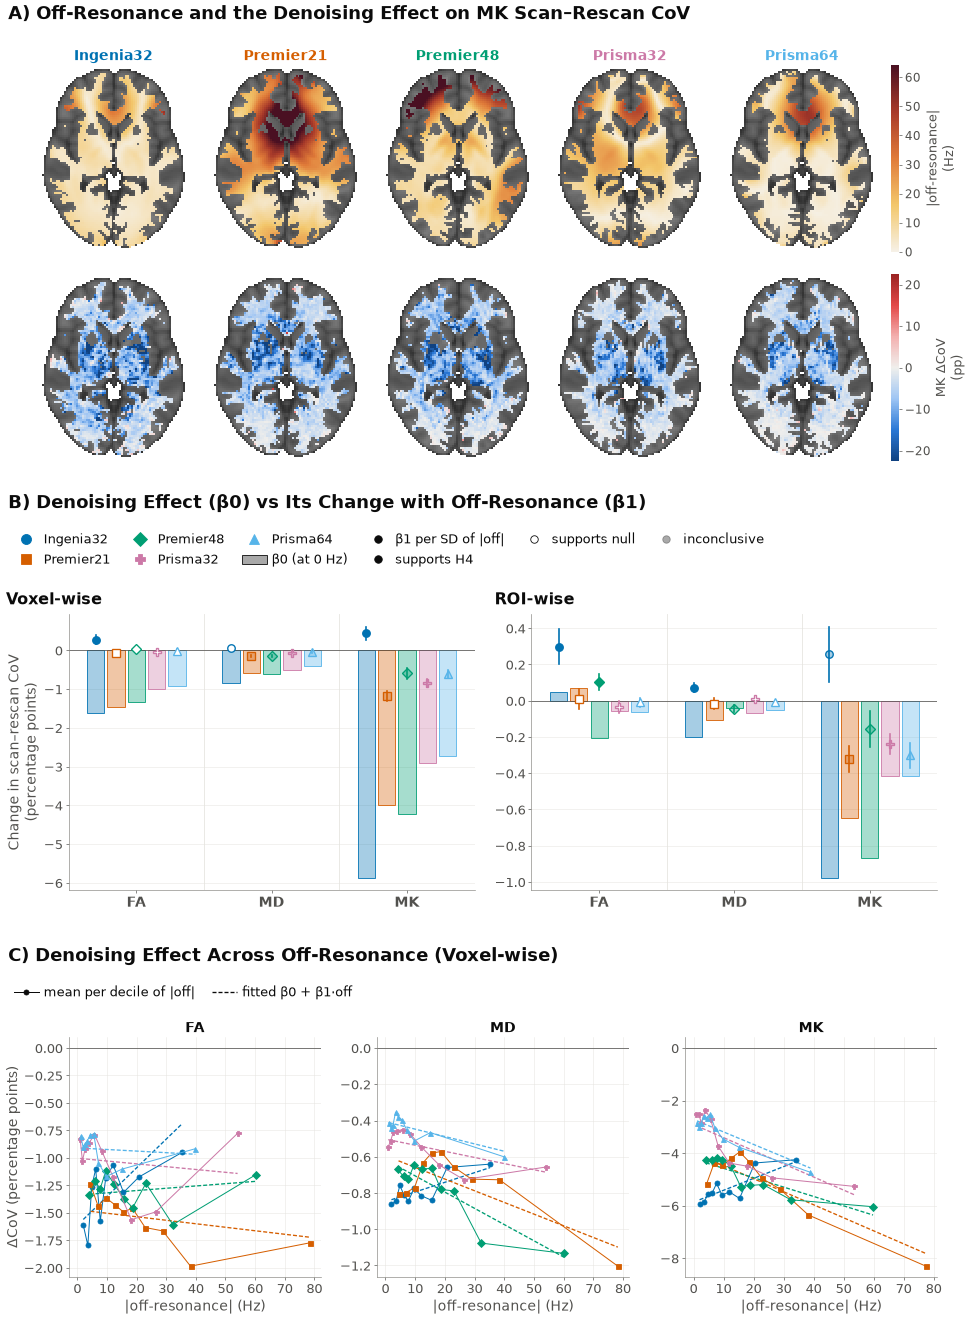

In [4]:
fig = figs.fig_h4(DERIV, METRICS, fs=16)
figs.save(fig, FIGS, "Fig5_H4")
plt.show()